# Módulo 54: Series de tiempo — Solución

Author: Juliho Castillo Colmenares Ph.D.

Enunciado para estudiantes: [m54-series-de-tiempo-guia.ipynb](m54-series-de-tiempo-guia.ipynb) · Lección: [m54-series-de-tiempo-leccion.ipynb](m54-series-de-tiempo-leccion.ipynb)

## Contexto

Un fondo de inversión tiene posiciones en **IBM** y **Walmart** y quiere entender cómo se han comportado sus acciones de 2019 a 2023: si sus precios se mueven juntos, si muestran tendencia o estacionalidad, si las series son estacionarias y cuál sería un pronóstico ingenuo para el siguiente día de negociación basado en promedios móviles.

## Datos

Precios diarios de `IBM` y `WMT` del 2019-01-01 al 2023-12-31, descargados de Yahoo Finance con `yfinance` (requiere internet). `Close` es el cierre ajustado (`auto_adjust=True`); las columnas tienen dos niveles (campo y ticker).

## Instrucciones

1. **Correlación entre IBM y Walmart:** precios de cierre alineados, correlación y diagrama de dispersión; correlación de los rendimientos diarios.
2. **Descomposición y autocorrelación:** descomposición aditiva con periodo de 252 días hábiles y correlograma con 40 rezagos.
3. **Prueba de estacionariedad de Dickey–Fuller** para cada precio de cierre.
4. **Promedio móvil de 30 días** y su gráfica junto al precio.
5. **Pronóstico a un día** con el último promedio móvil.

*El enunciado original del curso no se conserva; estas instrucciones se reconstruyeron a partir de la solución.* El material del módulo (Buenas prácticas) confirma que la tarea asignada consistía en analizar y pronosticar con promedios móviles el precio de las acciones de IBM y Walmart.


### Descarga de los datos

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
# Step 1: Download historical data
start_date = "2019-01-01"
end_date = "2024-01-01"

In [3]:
ibm_data = yf.download("IBM", start=start_date, end=end_date)
ibm_data

[*********************100%***********************]  1 of 1 completed

Price,Close,High,Low,Open,Volume
Ticker,IBM,IBM,IBM,IBM,IBM
Date,,,,,
2019-01-02,79.572502,80.104321,77.141334,77.362347,4434935
2019-01-03,77.983986,79.344616,77.832036,79.102879,4546648
2019-01-04,81.029854,81.147267,79.040711,79.365329,4683779
2019-01-07,81.603096,82.072758,80.580902,81.154159,3923755
2019-01-08,82.763435,83.274535,82.176366,82.646023,4982726
...,...,...,...,...,...
2023-12-22,149.496460,149.745410,148.445357,148.537564,2442700
2023-12-26,150.483032,150.575226,149.413485,149.579442,1772400


In [4]:
walmart_data = yf.download("WMT", start=start_date, end=end_date)
walmart_data

[*********************100%***********************]  1 of 1 completed

Price,Close,High,Low,Open,Volume
Ticker,WMT,WMT,WMT,WMT,WMT
Date,,,,,
2019-01-02,27.847111,27.939597,27.339933,27.339933,24458100
2019-01-03,27.703909,28.255839,27.656174,27.808328,24831900
2019-01-04,27.876942,27.942575,27.653186,27.808322,24087300
2019-01-07,28.205120,28.393076,27.799377,27.930648,23369100
2019-01-08,28.402027,28.569098,28.017167,28.360259,21602700
...,...,...,...,...,...
2023-12-22,50.785576,50.947672,50.302522,50.396537,19405500
2023-12-26,50.707764,50.895801,50.610506,50.785573,11679900


### Tarea 1. Correlación entre IBM y Walmart

In [5]:
# Step 2: Correlation Analysis

# Create DataFrames from the Close prices for alignment
ibm_close = ibm_data["Close"]["IBM"].to_frame()
ibm_close

,IBM
Date,
2019-01-02,79.572502
2019-01-03,77.983986
2019-01-04,81.029854
2019-01-07,81.603096
2019-01-08,82.763435
...,...
2023-12-22,149.496460
2023-12-26,150.483032
2023-12-27,150.713516


In [6]:
walmart_close = walmart_data["Close"]["WMT"].to_frame()
walmart_close

,WMT
Date,
2019-01-02,27.847111
2019-01-03,27.703909
2019-01-04,27.876942
2019-01-07,28.205120
2019-01-08,28.402027
...,...
2023-12-22,50.785576
2023-12-26,50.707764
2023-12-27,51.184345


In [7]:
aligned_data = ibm_close.join(walmart_close, how="inner").rename(
    columns={"IBM": "Close_IBM", "WMT": "Close_WMT"}
)
aligned_data

,Close_IBM,Close_WMT
Date,,
2019-01-02,79.572502,27.847111
2019-01-03,77.983986,27.703909
2019-01-04,81.029854,27.876942
2019-01-07,81.603096,28.205120
2019-01-08,82.763435,28.402027
...,...,...
2023-12-22,149.496460,50.785576
2023-12-26,150.483032,50.707764
2023-12-27,150.713516,51.184345


In [8]:
# Calculate the correlation between IBM and Walmart closing prices
correlation = aligned_data["Close_IBM"].corr(aligned_data["Close_WMT"])
correlation

np.float64(0.6661887108607333)

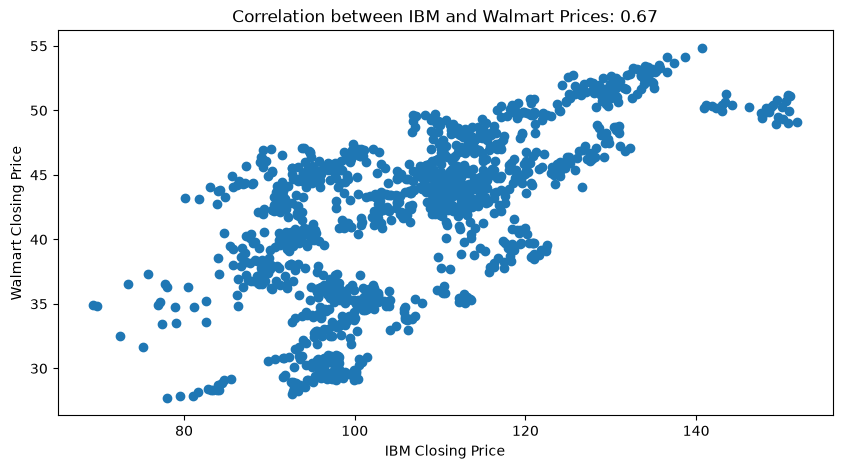

In [9]:
# Plot scatter plot for visual correlation
plt.figure(figsize=(10, 5))
plt.scatter(aligned_data["Close_IBM"], aligned_data["Close_WMT"])
plt.xlabel("IBM Closing Price")
plt.ylabel("Walmart Closing Price")
plt.title(f"Correlation between IBM and Walmart Prices: {correlation:.2f}")
plt.show()

In [10]:
# Correlation of daily returns: two trending price series can look correlated just
# because both drift over time, so we also compare their day-to-day changes
daily_returns = aligned_data.pct_change().dropna()
returns_correlation = daily_returns["Close_IBM"].corr(daily_returns["Close_WMT"])
returns_correlation

np.float64(0.3232353513225576)

### Tarea 2. Descomposición y autocorrelación

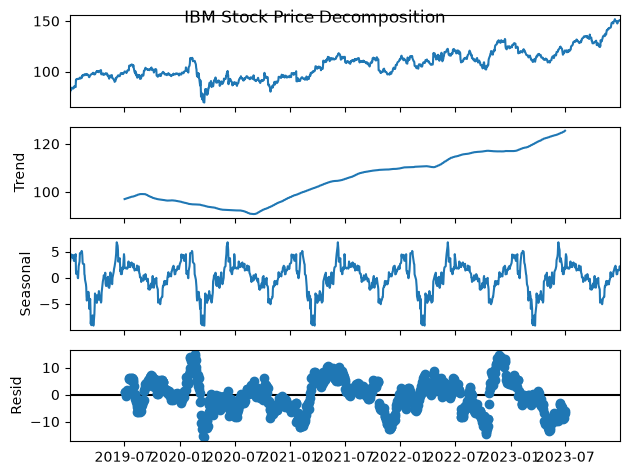

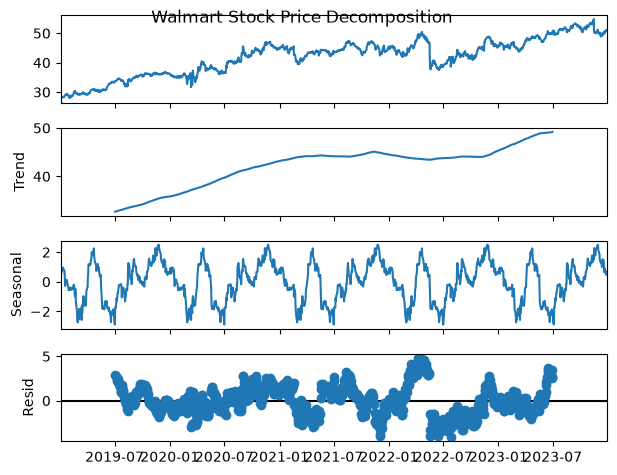

In [11]:
# Step 3: Time Series Decomposition
# Decompose both time series and plot
# period=252: the index only has trading days, about 252 per year (not 365)
for stock_data, name in zip([ibm_data, walmart_data], ["IBM", "Walmart"]):
    decomposed = seasonal_decompose(stock_data["Close"], model="additive", period=252)
    decomposed.plot()
    plt.suptitle(f"{name} Stock Price Decomposition")
    plt.show()

<Figure size 1000x500 with 0 Axes>

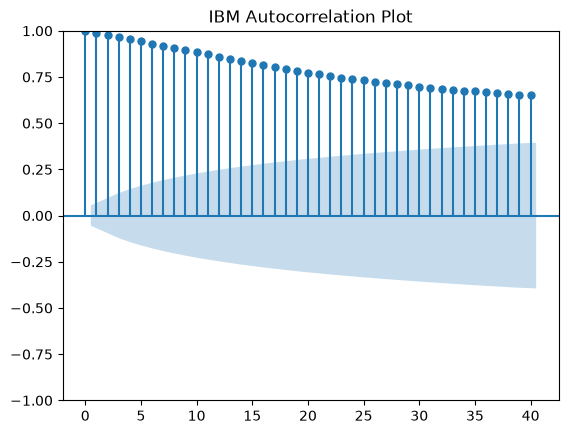

<Figure size 1000x500 with 0 Axes>

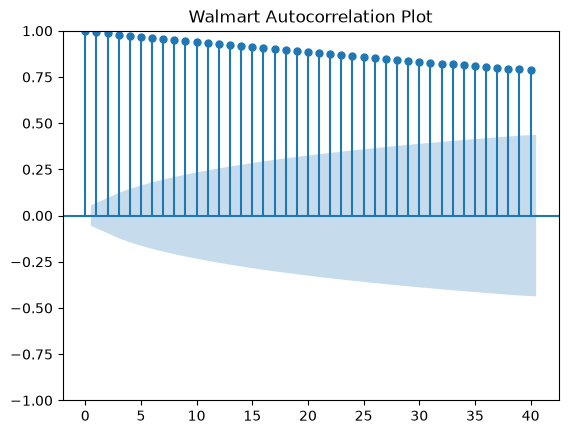

In [12]:
# Plot correlograms for both IBM and Walmart stock prices
for stock_data, name in zip([ibm_data, walmart_data], ["IBM", "Walmart"]):
    plt.figure(figsize=(10, 5))
    plot_acf(stock_data["Close"].dropna(), lags=40)
    plt.title(f"{name} Autocorrelation Plot")
    plt.show()

### Tarea 3. Prueba de estacionariedad de Dickey–Fuller

In [13]:
# Step 4: Dickey-Fuller Test for stationarity
def adf_test(series, name):
    result = adfuller(series)
    print(f"ADF Statistic for {name}: {result[0]}")
    print(f"p-value for {name}: {result[1]}")
    if result[1] < 0.05:
        print(f"The {name} series is stationary.")
    else:
        print(f"The {name} series is not stationary.")

In [14]:
adf_test(ibm_data["Close"], "IBM")
adf_test(walmart_data["Close"], "Walmart")

ADF Statistic for IBM: -1.4646554585711438
p-value for IBM: 0.550917743719192
The IBM series is not stationary.
ADF Statistic for Walmart: -1.8881389478156843
p-value for Walmart: 0.33766133154567335
The Walmart series is not stationary.


### Tarea 4. Promedio móvil de 30 días

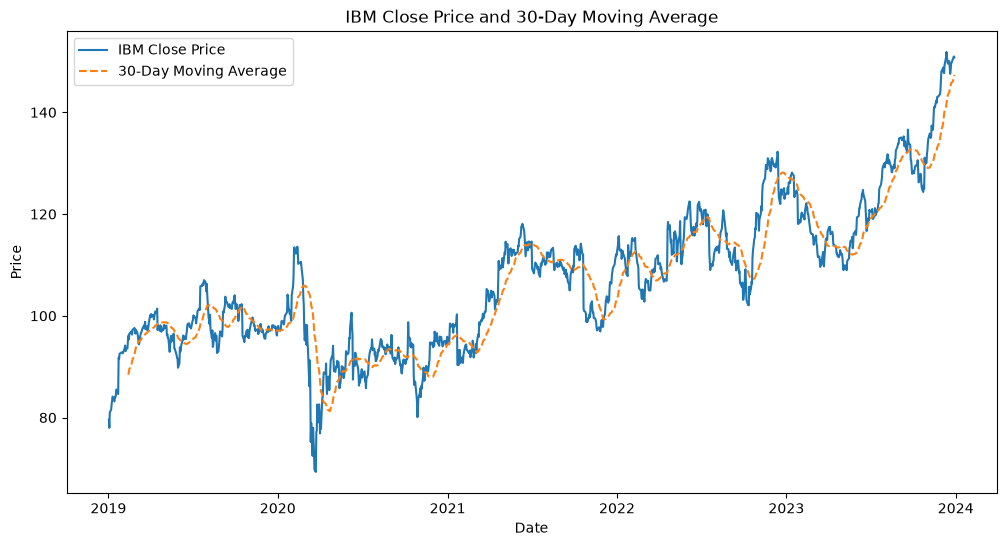

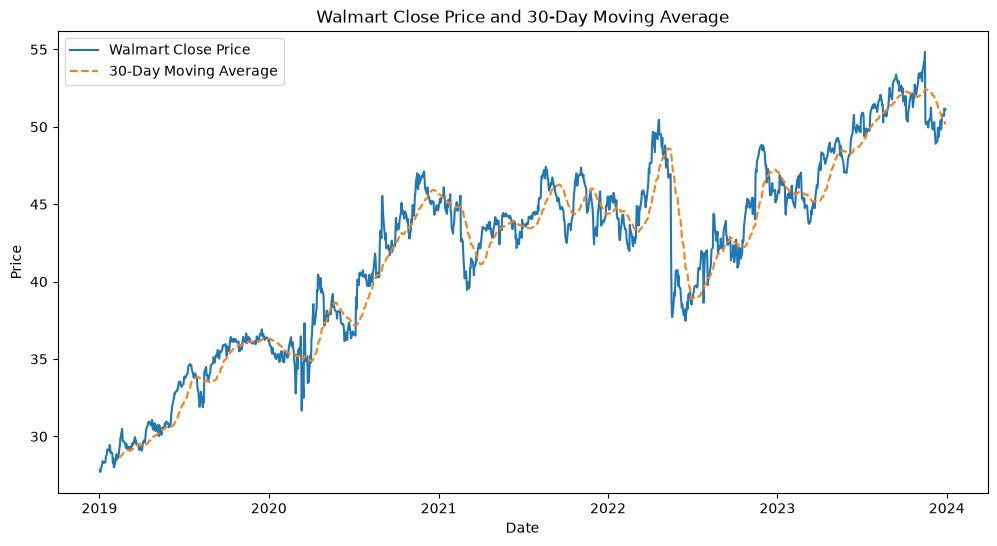

In [15]:
# Step 5: Moving Average Analysis
# Calculate 30-day moving average for both stocks
for stock_data, name in zip([ibm_data, walmart_data], ["IBM", "Walmart"]):
    stock_data["30_day_MA"] = stock_data["Close"].rolling(window=30).mean()

    # Plot original and moving average prices
    plt.figure(figsize=(12, 6))
    plt.plot(stock_data["Close"], label=f"{name} Close Price")
    plt.plot(stock_data["30_day_MA"], label="30-Day Moving Average", linestyle="--")
    plt.title(f"{name} Close Price and 30-Day Moving Average")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.show()

### Tarea 5. Pronóstico a un día

In [16]:
# Step 6: One-Day Forecast (simple projection using last moving average value)
# For simplicity, we use the last available 30-day moving average as the forecast
for stock_data, name in zip([ibm_data, walmart_data], ["IBM", "Walmart"]):
    last_moving_avg = stock_data["30_day_MA"].iloc[-1]
    print(
        f"One-day forecast for {name} based on the 30-day moving average: {last_moving_avg}"
    )

One-day forecast for IBM based on the 30-day moving average: 147.35214131673177
One-day forecast for Walmart based on the 30-day moving average: 50.15185101826986


**Revisión posterior (2026-10):** se añadió la correlación de los rendimientos diarios, además de la de los precios, y la descomposición estacional usa `period=252` (días hábiles por año) en lugar de 365, porque la serie solo tiene días de negociación. Al re-ejecutar, yfinance devuelve precios `Close` ya ajustados (`auto_adjust`), así que las cifras difieren de la versión entregada: la correlación de precios pasa de 0.25 a 0.67 (la de rendimientos es 0.32) y la prueba ADF ya no rechaza la raíz unitaria para IBM. El PDF conserva la versión entregada.